In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

In [2]:
df = pd.read_csv("survey_results_public.csv", low_memory=False)

In [3]:
df.shape

(30903, 212)

In [4]:
df.head()

,ResponseId,Age,CodeMain,Education,Employment,EmploymentAddl,ICorPM,WorkSetting,LearnCode,LearnCodeHow,...,KnowledgeSourceAI,KnowAgentDelegate,KnowledgeA,TrustReason,KnowAgentTrust,ContextSelect,ContextProblems,ContextFreq,ContextWork,ConvertedCompYearly
0,1,35-44 years old,I create code as a primary part of my job,"Master's degree (M.A., M.S., M.Eng., MBA, etc.)","Independent contractor, freelancer, or self-em...",None of the above,Individual contributor in a senior or staff-le...,"Hybrid (some remote, leans heavy to in-person)",Yes,AI codegen tools or AI-enabled apps,...,Important,"Planning, scoping, or estimating work",NaN,I know who created or owns it,The AI tool chooses the information automatically,Current status or ownership,I do not know where to look,Rarely,Manually select files or documents for AI tools,NaN
1,2,45-54 years old,I create code as a primary part of my job,"Master's degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,"Caring for dependents (children, elderly, etc.)",Individual contributor,Remote,No,NaN,...,Very important,"Investigating an incident, outage, or producti...",NaN,It comes from an official or trusted source;It...,I do not use AI tools or agents for work,"Code, repositories, or technical documentation...",Different teams have different versions of the...,Often,NaN,NaN
2,3,65 years or older,I create code as a primary part of my job,"Master's degree (M.A., M.S., M.Eng., MBA, etc.)",Retired,Volunteering (regularly),NaN,NaN,No,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10000.0
3,4,Under 18 years old,I create code as a primary part of my job,Primary/elementary school,Student,Attending school (full-time);Volunteering (reg...,NaN,NaN,Yes,AI codegen tools or AI-enabled apps;Colleague ...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,45-54 years old,I create code as a primary part of my job,"Bachelor's degree (B.A., B.S., B.Eng., etc.)",Employed,None of the above,Individual contributor in a senior or staff-le...,Remote,No,NaN,...,Very important,"Reviewing code, pull requests, or technical ch...",4.0,I know who created or owns it;It includes sour...,I decide exactly what information to give the ...,"Code, repositories, or technical documentation...",Information is incomplete;Information is outda...,Often,Keep notes or prompts in a separate document,85296.0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30903 entries, 0 to 30902
Columns: 212 entries, ResponseId to ConvertedCompYearly
dtypes: float64(14), int64(1), object(197)
memory usage: 50.0+ MB


In [6]:
df.describe()

,ResponseId,YearsCode,WorkExp,JobSat,JobEaseAI_7,JobEaseAI_9,JobEaseAI_10,JobDifficultyAI_8,JobDifficultyAI_9,JobDifficultyAI_10,ToolCount,Compensation,AIToolCount,KnowledgeA,ConvertedCompYearly
count,30903.000000,25204.000000,24607.000000,18876.000000,0.0,0.0,0.0,0.0,0.0,0.0,14836.000000,1.444700e+04,1.191900e+04,12006.000000,1.350700e+04
mean,15452.000000,17.330662,14.257325,6.955181,NaN,NaN,NaN,NaN,NaN,NaN,34.868226,6.921852e+101,9.230786e+10,9.242879,1.065351e+05
std,8921.072021,12.033142,11.727927,2.152369,NaN,NaN,NaN,NaN,NaN,NaN,478.941445,8.319767e+103,9.205284e+12,8.269965,4.453677e+05
min,1.000000,1.000000,1.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000e+00,0.000000e+00,1.000000,1.000000e+00
25%,7726.500000,8.000000,5.000000,6.000000,NaN,NaN,NaN,NaN,NaN,NaN,4.000000,5.000000e+04,2.000000e+00,4.000000,4.137200e+04
50%,15452.000000,15.000000,12.000000,7.000000,NaN,NaN,NaN,NaN,NaN,NaN,6.000000,1.000000e+05,2.000000e+00,8.000000,7.961000e+04
75%,23177.500000,25.000000,20.000000,8.000000,NaN,NaN,NaN,NaN,NaN,NaN,10.000000,2.000000e+05,3.000000e+00,10.000000,1.263470e+05
max,30903.000000,100.000000,100.000000,10.000000,NaN,NaN,NaN,NaN,NaN,NaN,10000.000000,1.000000e+106,1.000000e+15,100.000000,3.191935e+07


In [7]:
df.isnull().sum()

ResponseId                 0
Age                        0
CodeMain                 109
Education                142
Employment                 0
                       ...  
ContextSelect          18225
ContextProblems        18529
ContextFreq            18216
ContextWork            18864
ConvertedCompYearly    17396
Length: 212, dtype: int64

In [8]:
missing = df.isnull().sum().sort_values(ascending=False)

missing.head(20)

JobEaseAI_7           30903
JobDifficultyAI_10    30903
JobDifficultyAI_9     30903
JobDifficultyAI_8     30903
JobEaseAI_9           30903
JobEaseAI_10          30903
KnowledgeSource_14    30814
KnowledgeTime_14      30810
KnowledgeAcc_14       30805
AIMemAdmired          30778
KnowledgeSource_15    30763
KnowledgeTime_15      30759
KnowledgeAcc_15       30754
KnowledgeSource_9     30575
AINoCodeAdmired       30573
KnowledgeTime_9       30562
KnowledgeAcc_9        30553
KnowledgeSource_13    30517
KnowledgeTime_13      30506
KnowledgeAcc_13       30500
dtype: int64

In [9]:
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing Count': missing,
    'Missing Percentage': missing_percent
})

missing_summary.head(20)

,Missing Count,Missing Percentage
AIAdopt,19441,62.909750
AIAutomateAdmired,29754,96.281914
AIAutomateHaveWorkedWith,27642,89.447626
AIAutomateWantToUseNext6Months,28617,92.602660
AIAvoid,17046,55.159693
AICodeAgentAdmired,25041,81.030968
AICodeAgentHaveWorkedWith,19164,62.013397
AICodeAgentWantToUseNext6Months,23255,75.251594
AIComplex,16562,53.593502
AICost,29870,96.657282


In [10]:
missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})

missing_summary = missing_summary.sort_values(
    by='Missing Percentage',
    ascending=False
)

missing_summary.head(20).round(2)

,Missing Count,Missing Percentage
JobEaseAI_7,30903,100.00
JobDifficultyAI_10,30903,100.00
JobDifficultyAI_9,30903,100.00
JobDifficultyAI_8,30903,100.00
JobEaseAI_9,30903,100.00
JobEaseAI_10,30903,100.00
KnowledgeSource_14,30814,99.71
KnowledgeTime_14,30810,99.70
KnowledgeAcc_14,30805,99.68
AIMemAdmired,30778,99.60


In [11]:
df['Employment'].value_counts()

Employment
Employed                                                20259
Independent contractor, freelancer, or self-employed     4607
Student                                                  3139
Not employed                                             1742
Retired                                                   607
I prefer not to say                                       549
Name: count, dtype: int64

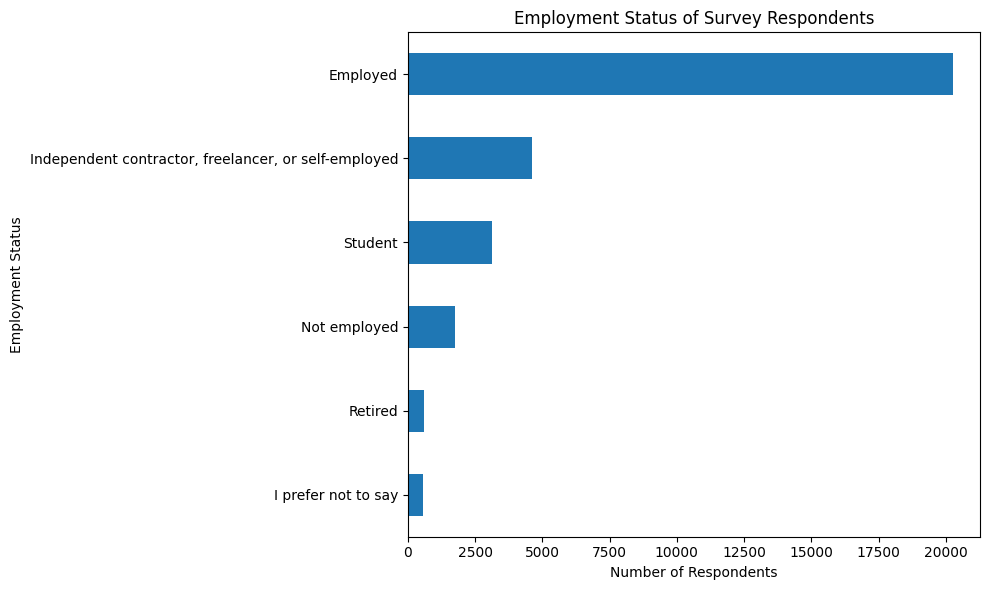

In [12]:
plt.figure(figsize=(10, 6))

employment_counts = df['Employment'].value_counts()

employment_counts.sort_values().plot(
    kind='barh'
)

plt.title('Employment Status of Survey Respondents')
plt.xlabel('Number of Respondents')
plt.ylabel('Employment Status')

plt.tight_layout()
plt.show()

In [13]:
df['Age'].value_counts().sort_index()

Age
18-24 years old       4944
25-34 years old       9267
35-44 years old       8522
45-54 years old       4198
55-64 years old       1829
65 years or older      822
Prefer not to say      352
Under 18 years old     969
Name: count, dtype: int64

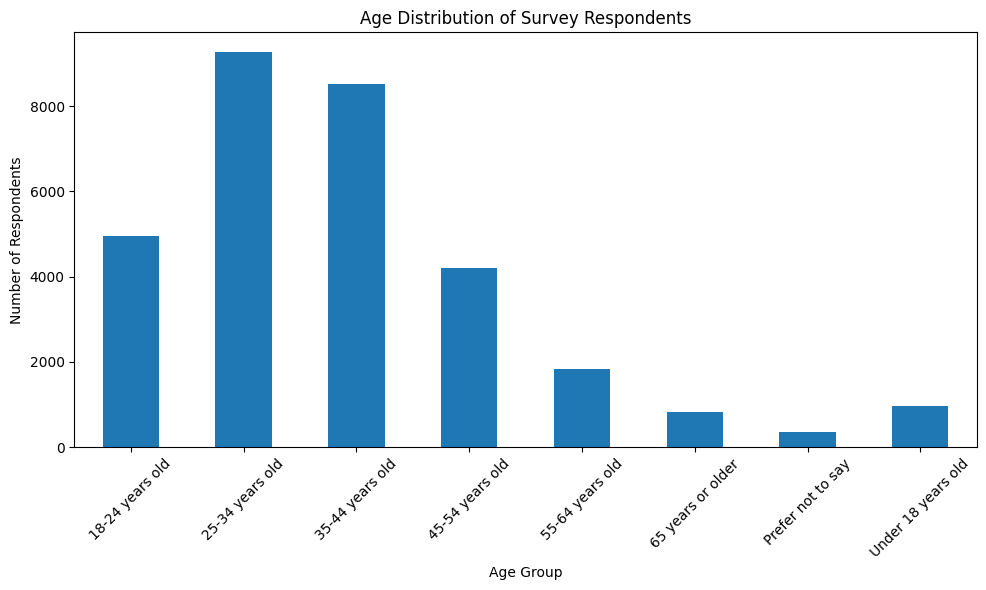

In [14]:
plt.figure(figsize=(10, 6))

df['Age'].value_counts().sort_index().plot(kind='bar')

plt.title('Age Distribution of Survey Respondents')
plt.xlabel('Age Group')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [15]:
df['Country'].value_counts().head(10)

Country
United States of America                                4755
Germany                                                 1983
United Kingdom of Great Britain and Northern Ireland    1374
India                                                   1309
Canada                                                   851
France                                                   794
Netherlands                                              577
Poland                                                   527
Australia                                                522
Ukraine                                                  484
Name: count, dtype: int64

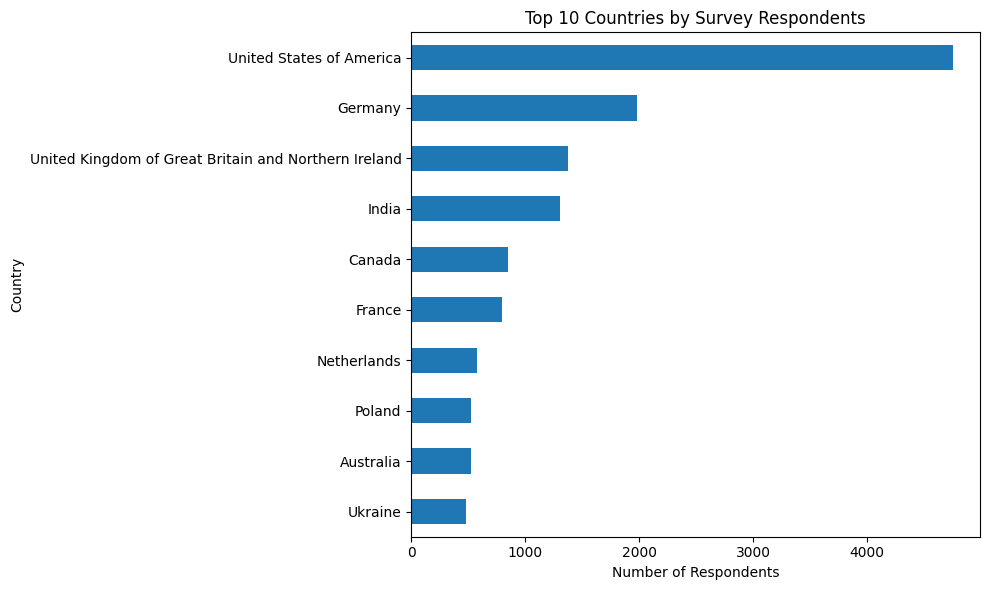

In [16]:
plt.figure(figsize=(10, 6))

country_counts = df['Country'].value_counts().head(10)

country_counts.sort_values().plot(kind='barh')

plt.title('Top 10 Countries by Survey Respondents')
plt.xlabel('Number of Respondents')
plt.ylabel('Country')

plt.tight_layout()
plt.show()

The country distribution shows that the United States contributes the largest number of survey responses, followed by Germany, the United Kingdom, and India. Respondent representation is uneven across countries, meaning that the overall survey findings may be influenced disproportionately by developers from countries with higher participation.

In [17]:
df['LanguagesHaveWorkedWith'].head()

0                                                  NaN
1                                                  NaN
2                                                  NaN
3    Bash/Shell (all shells);C++;Groovy;HTML/CSS;Ja...
4                                                  NaN
Name: LanguagesHaveWorkedWith, dtype: object

In [18]:
# Extract language responses
languages = df['LanguagesHaveWorkedWith'].dropna()

# Split each respondent's answer into individual languages
languages = languages.str.split(';')

# Flatten the lists into one Series
languages = languages.explode()

# Count each language
language_counts = languages.value_counts()

language_counts.head(15)

LanguagesHaveWorkedWith
JavaScript                 8742
SQL                        8237
HTML/CSS                   8211
Python                     8182
Bash/Shell (all shells)    7231
TypeScript                 6169
Java                       3884
C#                         3818
PowerShell                 3472
C++                        3425
C                          3070
Rust                       2540
PHP                        2490
Go                         2328
Kotlin                     1524
Name: count, dtype: int64

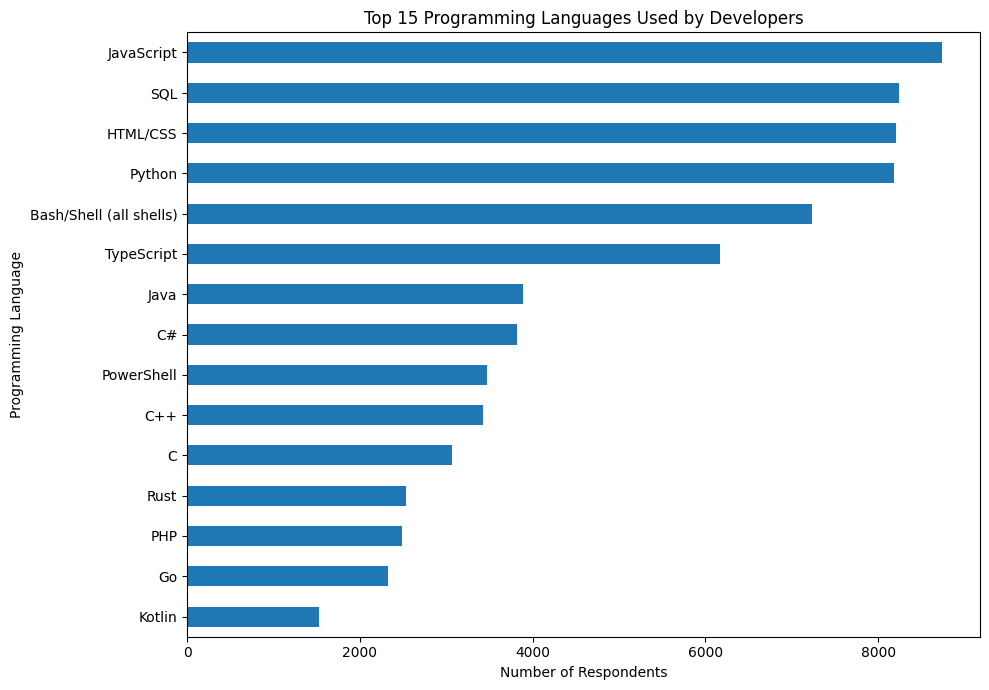

In [19]:
# Select the top 15 programming languages
top_languages = language_counts.head(15)

# Create a horizontal bar chart
plt.figure(figsize=(10, 7))

top_languages.sort_values().plot(kind='barh')

plt.title('Top 15 Programming Languages Used by Developers')
plt.xlabel('Number of Respondents')
plt.ylabel('Programming Language')

plt.tight_layout()
plt.show()

In [20]:
[col for col in df.columns if 'Database' in col]

['DatabasesHaveWorkedWith', 'DatabasesWantToWorkWith', 'DatabasesAdmired']

In [21]:
# Extract database responses
databases = df['DatabasesHaveWorkedWith'].dropna()

# Split multiple databases
databases = databases.str.split(';')

# Flatten the lists
databases = databases.explode()

# Count each database
database_counts = databases.value_counts()

# Display top 15
database_counts.head(15)

DatabasesHaveWorkedWith
PostgreSQL               6983
SQLite                   5081
MySQL                    4235
Redis                    3414
Microsoft SQL Server     3270
MariaDB                  2446
MongoDB                  2297
Elasticsearch            1784
Oracle                   1133
Dynamodb                 1116
Supabase                  933
BigQuery                  809
DuckDB                    690
Valkey                    603
Other, please specify     584
Name: count, dtype: int64

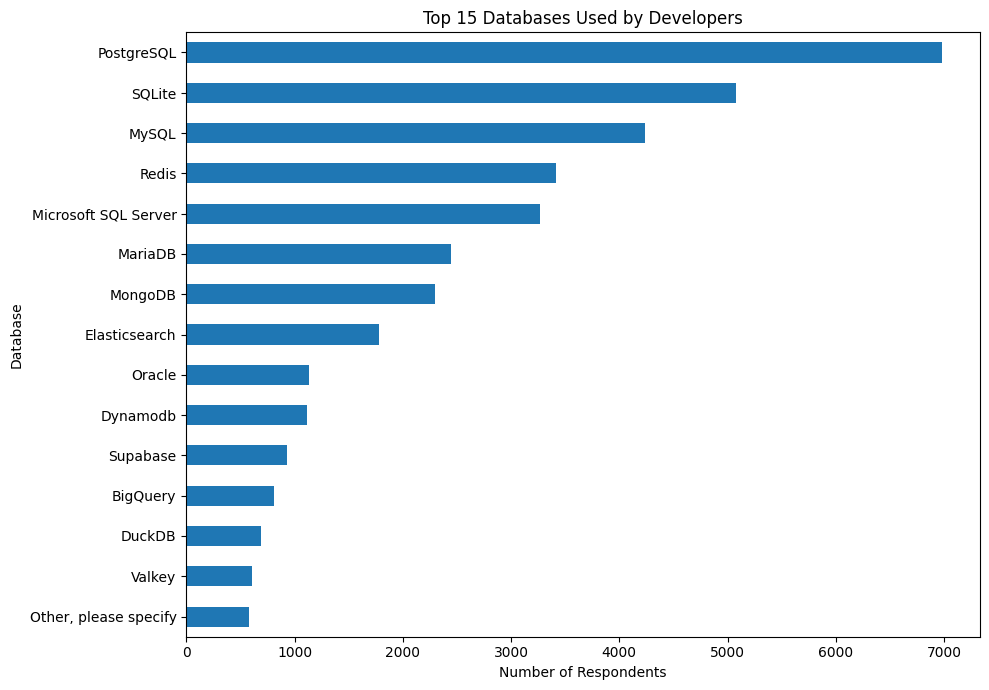

In [22]:
# Select the top 15 databases
top_databases = database_counts.head(15)

# Create horizontal bar chart
plt.figure(figsize=(10, 7))

top_databases.sort_values().plot(kind='barh')

plt.title('Top 15 Databases Used by Developers')
plt.xlabel('Number of Respondents')
plt.ylabel('Database')

plt.tight_layout()
plt.show()

In [23]:
# Extract desired database responses
databases_wanted = df['DatabasesWantToWorkWith'].dropna()

# Split multiple database responses
databases_wanted = databases_wanted.str.split(';')

# Flatten the lists
databases_wanted = databases_wanted.explode()

# Count each database
wanted_database_counts = databases_wanted.value_counts()

# Display top 15
wanted_database_counts.head(15)

DatabasesWantToWorkWith
PostgreSQL              5295
SQLite                  3468
Redis                   2475
MySQL                   1846
Microsoft SQL Server    1518
MongoDB                 1376
MariaDB                 1303
Elasticsearch           1182
DuckDB                   811
Supabase                 703
Dynamodb                 697
Valkey                   682
BigQuery                 598
Oracle                   499
Clickhouse               499
Name: count, dtype: int64

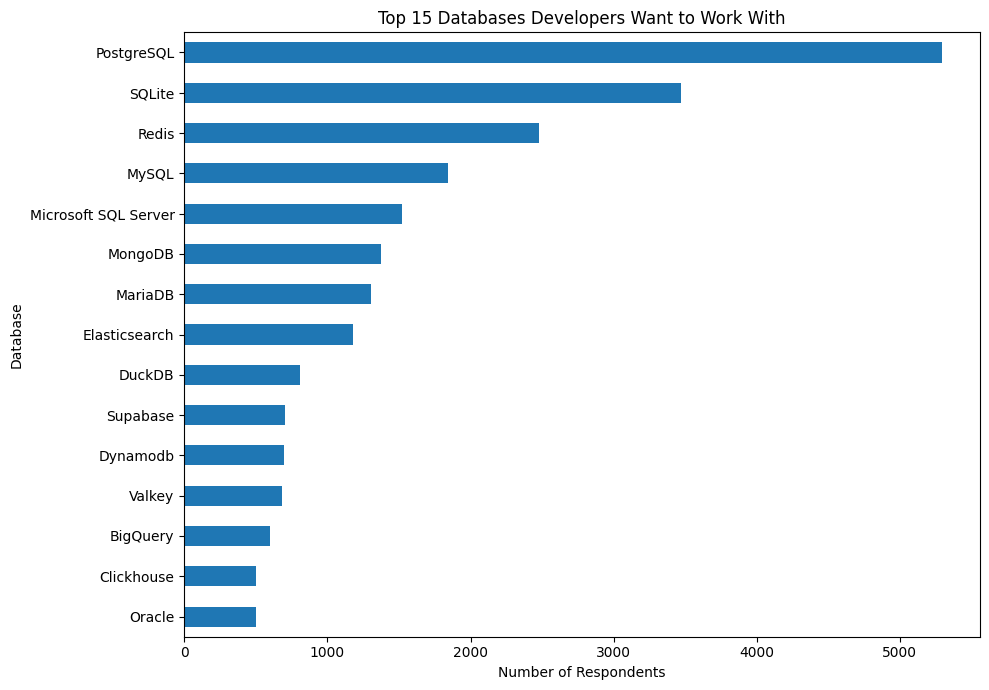

In [24]:
# Select the top 15 databases developers want to use
top_wanted_databases = wanted_database_counts.head(15)

# Create the chart
plt.figure(figsize=(10, 7))

top_wanted_databases.sort_values().plot(kind='barh')

plt.title('Top 15 Databases Developers Want to Work With')
plt.xlabel('Number of Respondents')
plt.ylabel('Database')

plt.tight_layout()
plt.show()

In [25]:
# Combine current usage and future interest
database_comparison = pd.DataFrame({
    'Currently Used': database_counts,
    'Want to Use': wanted_database_counts
})

# Replace missing values with 0
database_comparison = database_comparison.fillna(0)

# Sort by current usage and select top 10
database_comparison = database_comparison.sort_values(
    by='Currently Used', ascending=False
)

database_comparison.head(10)

,Currently Used,Want to Use
PostgreSQL,6983,5295
SQLite,5081,3468
MySQL,4235,1846
Redis,3414,2475
Microsoft SQL Server,3270,1518
MariaDB,2446,1303
MongoDB,2297,1376
Elasticsearch,1784,1182
Oracle,1133,499
Dynamodb,1116,697


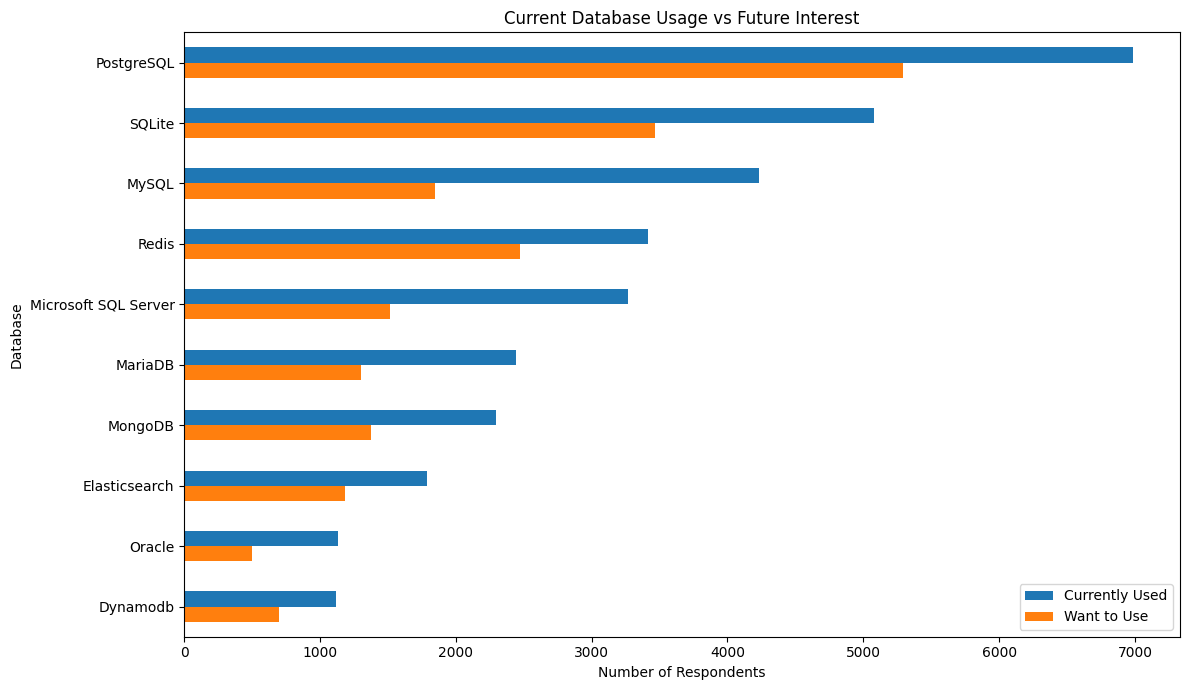

In [26]:
# Select top 10 databases
comparison_top10 = database_comparison.head(10)

# Plot comparison
comparison_top10.plot(
    kind='barh',
    figsize=(12, 7)
)

plt.title('Current Database Usage vs Future Interest')
plt.xlabel('Number of Respondents')
plt.ylabel('Database')
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [27]:
[col for col in df.columns if 'WorkExp' in col or 'Years' in col]

['YearsCode', 'WorkExp', 'SOYears', 'AIWorkExpectMore', 'AIWorkExpectLess']

In [29]:
# Compare work experience across employment categories
work_experience_by_employment = df.groupby('Employment')['WorkExp'].mean()

# Display the results
work_experience_by_employment.sort_values(ascending=False)

Employment
Retired                                                 36.019305
Independent contractor, freelancer, or self-employed    18.096494
I prefer not to say                                     16.779923
Employed                                                14.033359
Not employed                                            11.085194
Student                                                  2.660086
Name: WorkExp, dtype: float64

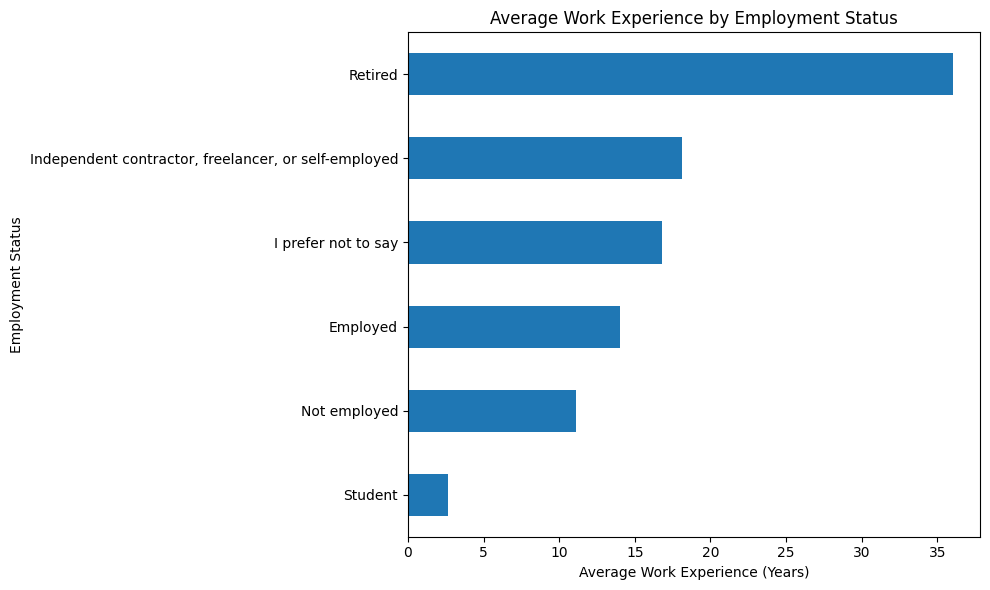

In [30]:
plt.figure(figsize=(10, 6))

work_experience_by_employment.sort_values().plot(kind='barh')

plt.title('Average Work Experience by Employment Status')
plt.xlabel('Average Work Experience (Years)')
plt.ylabel('Employment Status')

plt.tight_layout()
plt.show()

### Key Findings

The United States had the highest survey participation, with 4,755 respondents, followed by Germany with 1,983 and India with 1,309 respondents. JavaScript was the most frequently reported programming language with 8,742 responses, while Python also showed strong popularity with 8,182 responses. PostgreSQL was the most commonly reported database, with 6,983 respondents reporting current usage and 5,295 expressing future interest. The group analysis revealed substantial differences in professional experience by employment status, with retired respondents averaging 36.02 years of work experience compared with 2.66 years among students.